# 3. Machine Learning

**Goal:** predict each player's MVP vote share, then rank players to find the MVP.

- **Model:** LightGBM regressor
- **Train:** seasons 1991–2024
- **Test:** season 2025 (never seen during training)


## 1. Imports

In [1]:
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score, confusion_matrix, ConfusionMatrixDisplay

## 2. Load data

In [2]:
stats = pd.read_csv("player_mvp_stats.csv")

# The only missing values are shooting % for players with 0 attempts (0 / 0), so 0 is correct
stats = stats.fillna(0)
stats.shape

(16377, 40)

## 3. Features

Raw stats aren't comparable across eras (25 points per game means more in a low-scoring season).
So each key stat is also divided by that season's league average: `PTS_R = 2.0` means twice the league average that season.

Columns that are text, or that contain the answer (`Share`, `Pts Won`, `Pts Max`), are never used as features.

In [3]:
for col in ["PTS", "AST", "TRB", "STL", "BLK", "W/L%", "MP", "FG%"]:
    stats[f"{col}_R"] = stats[col] / stats.groupby("Year")[col].transform("mean")

target = "Share"   # MVP vote share, 0 to 1
not_features = ["Player", "Team", "Pos", "Year", "Pts Won", "Pts Max", "Share"]
predictors = [c for c in stats.columns if c not in not_features]

print(len(predictors), "features")

41 features


## 4. Train / test split

Split **by season**, not randomly. A random split would let the model learn from future seasons and would break up each season's MVP race.

In [4]:
train = stats[stats["Year"] <= 2024]
test = stats[stats["Year"] == 2025].copy()

print("Train:", train.shape, " seasons 1991-2024")
print("Test: ", test.shape, " season 2025")

Train: (15808, 48)  seasons 1991-2024
Test:  (569, 48)  season 2025


## 5. Train the model

In [5]:
# Chosen by tune_hyperparameters.py using only seasons 1991-2024 (rolling validation).
# Neither 2025 nor 2026 was used to pick these values.
with open("best_params.json") as f:
    best_params = json.load(f)["params"]

model = lgb.LGBMRegressor(**best_params, random_state=42, verbose=-1)

loss_history = {}
model.fit(
    train[predictors], train[target],
    eval_set=[(train[predictors], train[target]), (test[predictors], test[target])],
    eval_names=["train", "test"],
    eval_metric="l2",                                  # l2 = mean squared error
    callbacks=[lgb.record_evaluation(loss_history)],   # save the loss after every tree
)

lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


,num_leaves,9
,learning_rate,0.08918073675381503
,n_estimators,494
,min_child_samples,39
,subsample,0.8913676136251432
,subsample_freq,1
,colsample_bytree,0.5413649999612193
,random_state,42
,verbose,-1
,boosting_type,'gbdt'
,max_depth,-1


## 6. Loss curve

Loss = **mean squared error (MSE)** between predicted and actual vote share, measured after each tree.
Both curves go down and flatten: the model learned without overfitting.
(The test curve is only plotted; it was not used to choose anything.)

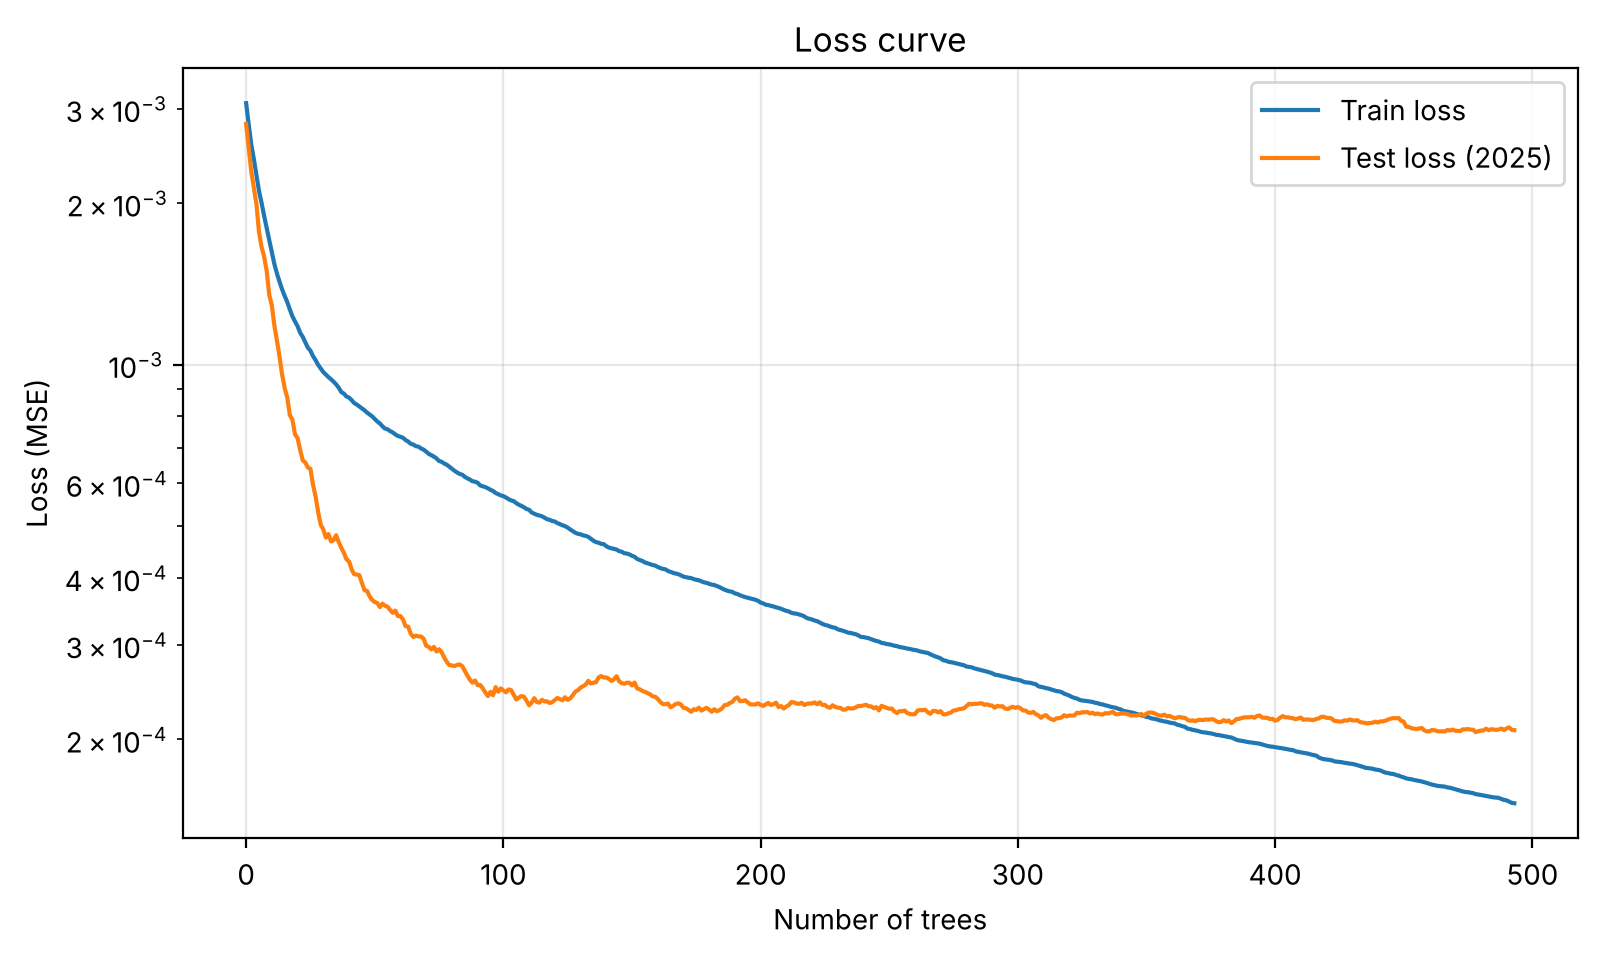

Final train loss (MSE): 0.000152
Final test loss  (MSE): 0.000208


In [6]:
plt.figure(figsize=(9, 5))
plt.plot(loss_history["train"]["l2"], label="Train loss")
plt.plot(loss_history["test"]["l2"], label="Test loss (2025)")
plt.xlabel("Number of trees")
plt.ylabel("Loss (MSE)")
plt.title("Loss curve")
plt.yscale("log")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

print(f"Final train loss (MSE): {loss_history['train']['l2'][-1]:.6f}")
print(f"Final test loss  (MSE): {loss_history['test']['l2'][-1]:.6f}")

## 7. Predict 2025

In [7]:
test["Predicted"] = model.predict(test[predictors])
test["Predicted rank"] = test["Predicted"].rank(ascending=False, method="first").astype(int)
test["Actual rank"] = test["Share"].rank(ascending=False, method="first").astype(int)

## 8. Results: actual vs predicted

In [8]:
(test.sort_values("Predicted", ascending=False)
     [["Player", "Team", "Predicted", "Share", "Predicted rank", "Actual rank"]]
     .rename(columns={"Share": "Actual"})
     .head(10)
     .round(3)
     .reset_index(drop=True))

,Player,Team,Predicted,Actual,Predicted rank,Actual rank
0,Shai Gilgeous-Alexander,Oklahoma City Thunder,0.860,0.913,1,1
1,Nikola Jokić,Denver Nuggets,0.602,0.787,2,2
2,Giannis Antetokounmpo,Milwaukee Bucks,0.365,0.470,3,3
3,Jayson Tatum,Boston Celtics,0.197,0.311,4,4
4,Trae Young,Atlanta Hawks,0.109,0.000,5,26
5,Donovan Mitchell,Cleveland Cavaliers,0.086,0.074,6,5
6,Karl-Anthony Towns,New York Knicks,0.065,0.000,7,23
7,Franz Wagner,Orlando Magic,0.057,0.000,8,25
8,Luka Dončić,Los Angeles Lakers,0.054,0.000,9,13
9,James Harden,Los Angeles Clippers,0.045,0.001,10,11


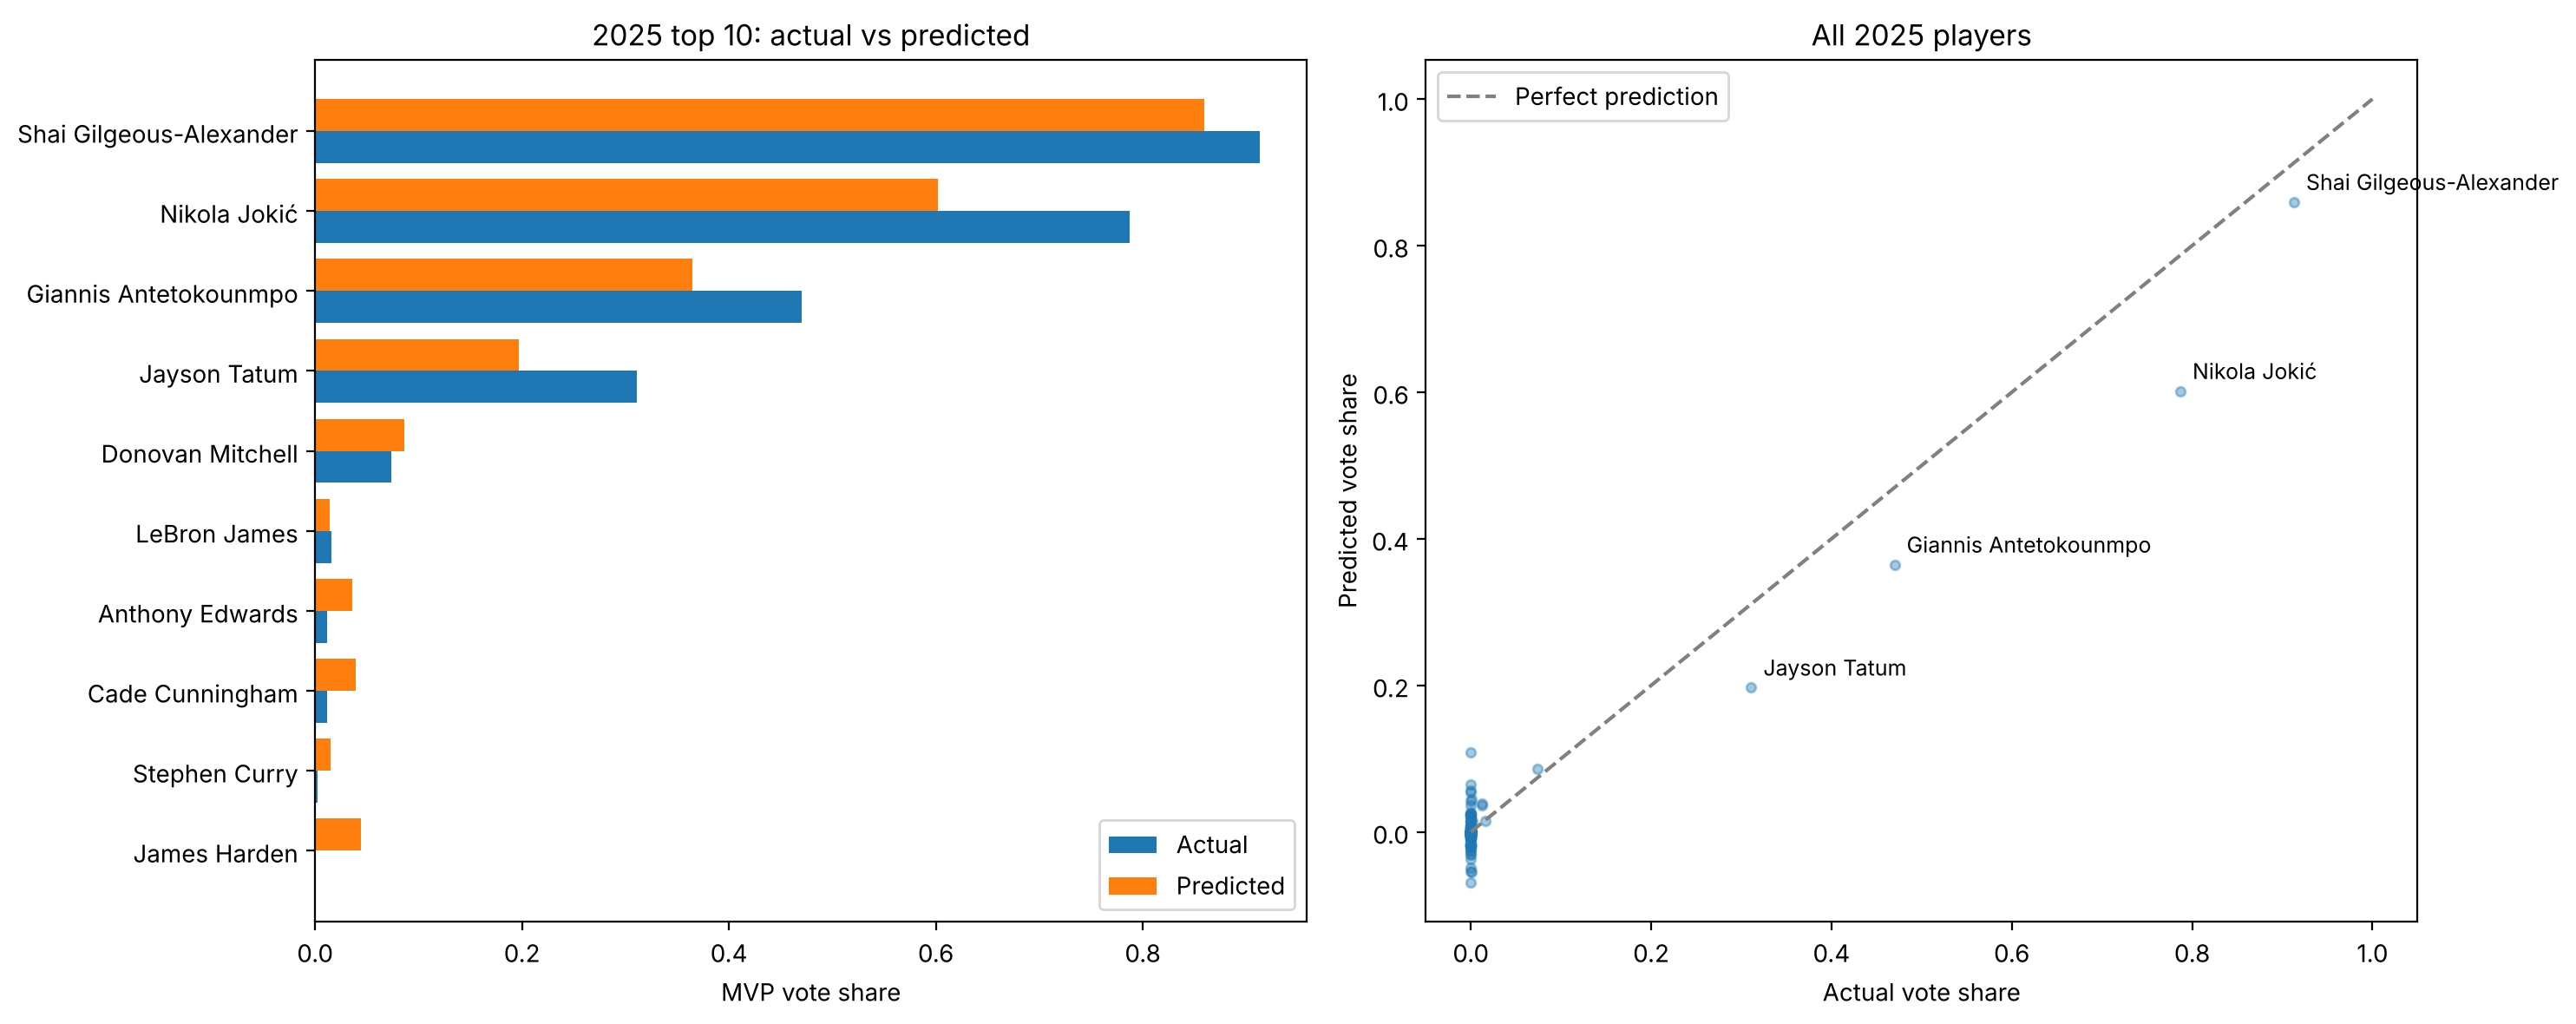

In [9]:
top = test.sort_values("Share", ascending=False).head(10).iloc[::-1]
y = np.arange(len(top))

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

axes[0].barh(y - 0.2, top["Share"], height=0.4, label="Actual")
axes[0].barh(y + 0.2, top["Predicted"], height=0.4, label="Predicted")
axes[0].set_yticks(y)
axes[0].set_yticklabels(top["Player"])
axes[0].set_xlabel("MVP vote share")
axes[0].set_title("2025 top 10: actual vs predicted")
axes[0].legend()

axes[1].scatter(test["Share"], test["Predicted"], alpha=0.4, s=15)
axes[1].plot([0, 1], [0, 1], "--", color="gray", label="Perfect prediction")
for _, row in test.sort_values("Share", ascending=False).head(4).iterrows():
    axes[1].annotate(row["Player"], (row["Share"], row["Predicted"]), xytext=(5, 5), textcoords="offset points", fontsize=9)
axes[1].set_xlabel("Actual vote share")
axes[1].set_ylabel("Predicted vote share")
axes[1].set_title("All 2025 players")
axes[1].legend()

plt.tight_layout()
plt.show()

## 9. Scores

- **MSE / RMSE / MAE:** how far predicted vote shares are from the real ones (lower is better)
- **R²:** share of the variation the model explains (1.0 = perfect)
- **MVP correct:** did the model's #1 pick win?
- **Top-5 accuracy:** how many of the real top 5 are in the predicted top 5

In [10]:
mse = mean_squared_error(test["Share"], test["Predicted"])

predicted_mvp = test.loc[test["Predicted rank"] == 1, "Player"].iloc[0]
actual_mvp = test.loc[test["Actual rank"] == 1, "Player"].iloc[0]
top5_hits = len(set(test.loc[test["Predicted rank"] <= 5, "Player"]) &
                set(test.loc[test["Actual rank"] <= 5, "Player"]))

pd.Series({
    "MSE (loss)": round(mse, 5),
    "RMSE": round(np.sqrt(mse), 4),
    "MAE": round(mean_absolute_error(test["Share"], test["Predicted"]), 4),
    "R²": round(r2_score(test["Share"], test["Predicted"]), 3),
    "Predicted MVP": predicted_mvp,
    "Actual MVP": actual_mvp,
    "MVP correct": predicted_mvp == actual_mvp,
    "Top-5 accuracy": f"{top5_hits}/5 ({top5_hits / 5:.0%})",
}, name="2025 test").to_frame()

,2025 test
MSE (loss),0.00021
RMSE,0.0144
MAE,0.0037
R²,0.933
Predicted MVP,Shai Gilgeous-Alexander
Actual MVP,Shai Gilgeous-Alexander
MVP correct,True
Top-5 accuracy,4/5 (80%)


## 10. Confusion matrix: top-5 contenders

Each player is labeled **Top 5** or **Not top 5**, once by the real votes and once by the model.

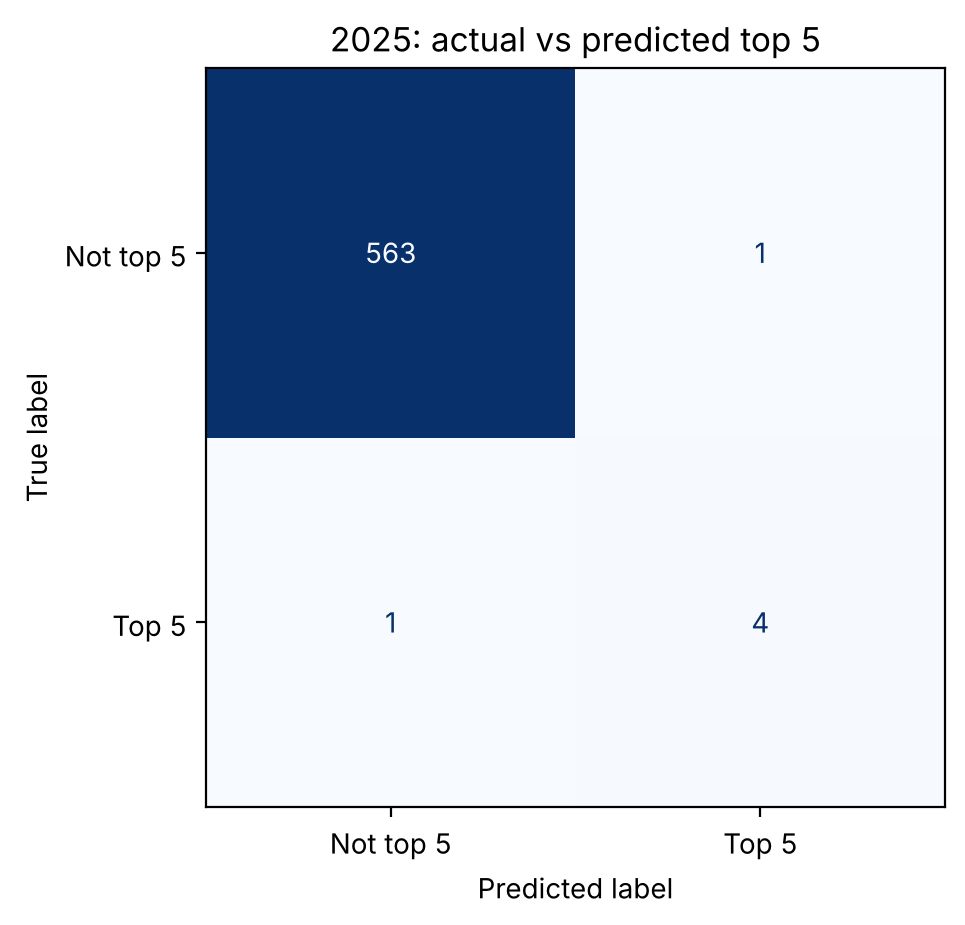

In [11]:
cm = confusion_matrix(test["Actual rank"] <= 5, test["Predicted rank"] <= 5)
ConfusionMatrixDisplay(cm, display_labels=["Not top 5", "Top 5"]).plot(cmap="Blues", colorbar=False)
plt.title("2025: actual vs predicted top 5")
plt.show()

## 11. Save the final model

Testing is done, so the final model is retrained on **all** seasons (1991–2025) with the same parameters,
then saved together with its feature list. `04_test_2026_season.ipynb` loads this file to predict a new season.

In [12]:
final_model = lgb.LGBMRegressor(**best_params, random_state=42, verbose=-1)
final_model.fit(stats[predictors], stats[target])

joblib.dump({"model": final_model, "predictors": predictors}, "mvp_model.joblib")
print("Saved mvp_model.joblib with", len(predictors), "features")

Saved mvp_model.joblib with 41 features


## Summary

- **2025 test:** MVP correct (Shai Gilgeous-Alexander); the top 4 are in the right order and 4 of the real top 5 are found (Trae Young is predicted 5th, Donovan Mitchell 6th).
- Hyperparameters were tuned only on seasons up to 2024 (`tune_hyperparameters.py`), so 2025 is a clean test.
- The 2026 test (`04_test_2026_season.ipynb`) is a second unseen season.
- **Typical misses:** players whose MVP case rests on advanced or defensive impact, which basic box-score stats don't capture.